# Titanic Dataset - Exploratory Data Analysis (EDA)

In [64]:
import pandas as pd

In [65]:
import os

In [66]:
os.getcwd()

'C:\\Users\\hp'

In [67]:
df=pd.read_csv(r"C:\Users\hp\Downloads\archive\Titanic-Dataset.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [68]:
df.shape

(891, 12)

In [69]:
df.columns


Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [70]:
df.info

<bound method DataFrame.info of      PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  26.0      0   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                             Allen, Mr. William Henry    male  35.0      0   
..                                   

In [71]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [72]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [73]:
print("Mean age:",df["Age"].mean())

Mean age: 29.69911764705882


In [74]:
print("median age:",df['Age'].median())

median age: 28.0


In [75]:
print("age variance:",df["Age"].var())

age variance: 211.01912474630802


In [76]:
print("standard deviation:",df["Age"].std())

standard deviation: 14.526497332334042


In [77]:
df['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [78]:
df['Pclass'].value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

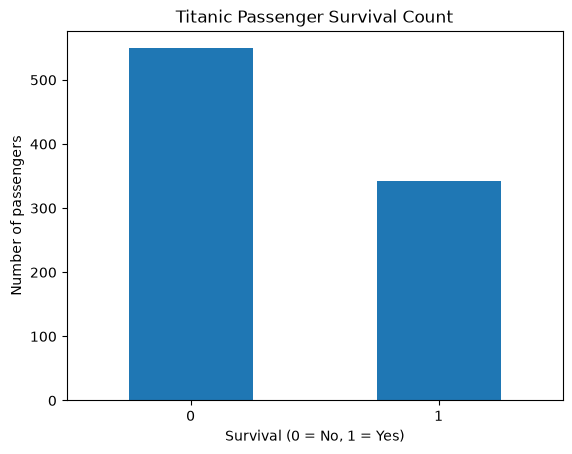

In [79]:
import matplotlib.pyplot as plt
df["Survived"].value_counts().sort_index().plot(kind="bar")
plt.title("Titanic Passenger Survival Count")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of passengers")
plt.xticks(rotation=0)
plt.show()

In [80]:
survival_percentage=df["Survived"].value_counts(normalize=True)*100
print(survival_percentage)

Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


In [81]:
pd.crosstab(df["Sex"],df["Survived"])

Survived,0,1
Sex,,
female,81,233
male,468,109


In [82]:
pd.crosstab(df['Sex'],df['Survived'],normalize='index')*100

Survived,0,1
Sex,,
female,25.796178,74.203822
male,81.109185,18.890815


In [83]:
df.groupby("Survived")['Age'].mean()


Survived
0    30.626179
1    28.343690
Name: Age, dtype: float64

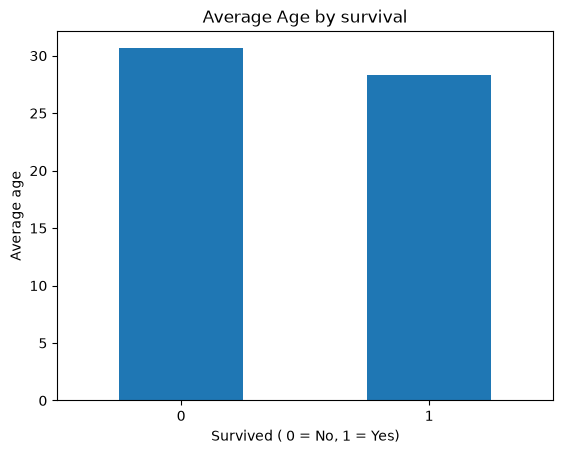

In [84]:
import matplotlib.pyplot as plt
df.groupby("Survived")["Age"].mean().plot(kind="bar")
plt.title("Average Age by survival")
plt.xlabel("Survived ( 0 = No, 1 = Yes)")
plt.ylabel("Average age")
plt.xticks(rotation=0)
plt.show()

In [85]:
pd.crosstab(df["Pclass"],df["Survived"])

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [86]:
pd.crosstab(df["Pclass"],df["Survived"],normalize="index")*100

Survived,0,1
Pclass,,
1,37.037037,62.962963
2,52.717391,47.282609
3,75.763747,24.236253


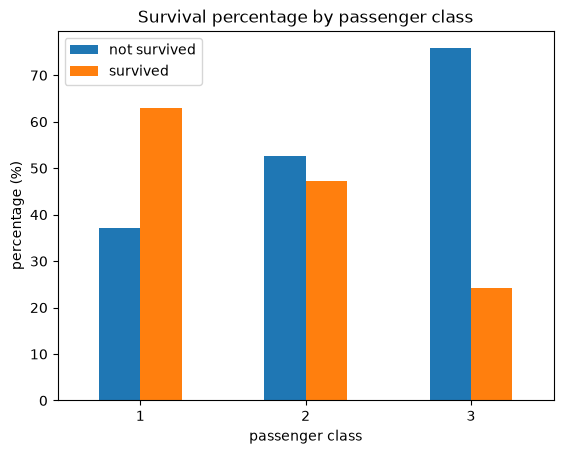

In [87]:
class_survival = pd.crosstab(
    df["Pclass"],
    df["Survived"],
    normalize="index"
) *100
class_survival.plot(kind="bar")
plt.title("Survival percentage by passenger class")
plt.xlabel("passenger class")
plt.ylabel("percentage (%)")
plt.xticks(rotation=0)
plt.legend(["not survived","survived"])
plt.show()

In [88]:
print("mean fare:",df["Fare"].mean())
print("Median fare:",df["Fare"].median())
print("maximum fare:",df["Fare"].max())
print("minimum fare:",df["Fare"].min())

mean fare: 32.204207968574636
Median fare: 14.4542
maximum fare: 512.3292
minimum fare: 0.0


Text(0, 0.5, 'Number of passengers')

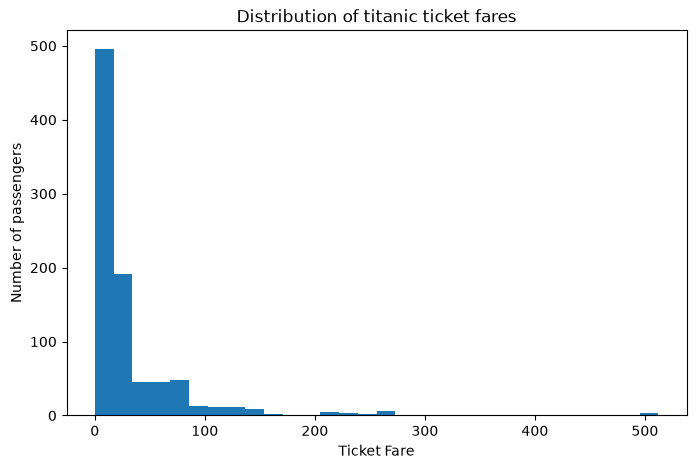

In [89]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,5))
plt.hist(df["Fare"].dropna(),bins=30)
plt.title("Distribution of titanic ticket fares")
plt.xlabel("Ticket Fare")
plt.ylabel("Number of passengers")

In [90]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [91]:
print(df["Age"].median())

28.0


In [92]:
df["Age"]=df["Age"].fillna(df["Age"].median())


In [93]:
df['Age'].isnull().sum()

np.int64(0)

In [94]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [95]:
df["Cabin"].fillna("0")

0         0
1       C85
2         0
3      C123
4         0
       ... 
886       0
887     B42
888       0
889    C148
890       0
Name: Cabin, Length: 891, dtype: str

In [96]:
df["Cabin"].isnull().sum()

np.int64(687)

In [97]:
print(df['Embarked'].mode()[0])

S


In [98]:
df['Embarked']=df['Embarked'].fillna(df['Embarked'].mode()[0])

In [99]:
print(df['Embarked'].isnull().sum())

0


In [100]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

In [101]:
print("Total missing cabin values:",df['Cabin'].isnull().sum())
print("Total rows:",len(df))
print("Unique cabin values:",df['Cabin'].nunique())

Total missing cabin values: 687
Total rows: 891
Unique cabin values: 147


In [102]:
print("duplicate rows:",df.duplicated().sum())

duplicate rows: 0


In [103]:
correlation= df.corr(numeric_only=True)
print(correlation)

             PassengerId  Survived    Pclass       Age     SibSp     Parch  \
PassengerId     1.000000 -0.005007 -0.035144  0.034212 -0.057527 -0.001652   
Survived       -0.005007  1.000000 -0.338481 -0.064910 -0.035322  0.081629   
Pclass         -0.035144 -0.338481  1.000000 -0.339898  0.083081  0.018443   
Age             0.034212 -0.064910 -0.339898  1.000000 -0.233296 -0.172482   
SibSp          -0.057527 -0.035322  0.083081 -0.233296  1.000000  0.414838   
Parch          -0.001652  0.081629  0.018443 -0.172482  0.414838  1.000000   
Fare            0.012658  0.257307 -0.549500  0.096688  0.159651  0.216225   

                 Fare  
PassengerId  0.012658  
Survived     0.257307  
Pclass      -0.549500  
Age          0.096688  
SibSp        0.159651  
Parch        0.216225  
Fare         1.000000  


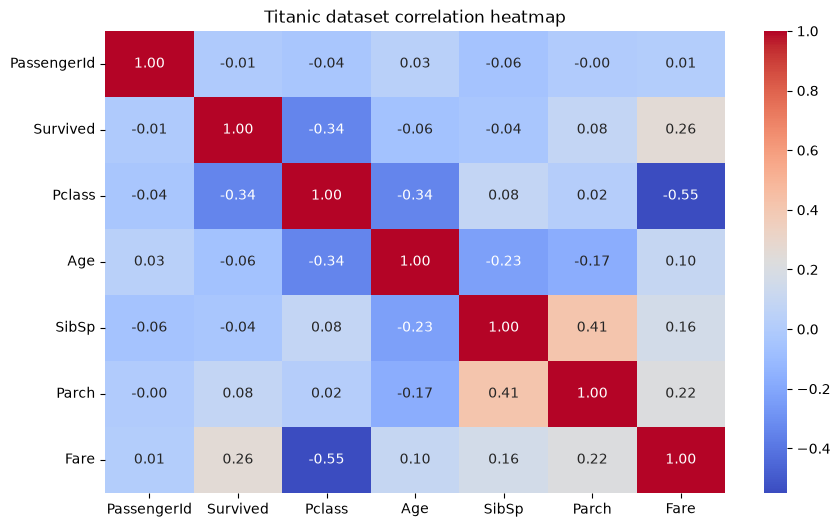

In [104]:
import seaborn as sd
import matplotlib.pyplot as plt
correlation= df.corr(numeric_only=True)
plt.figure(figsize=(10,6))
sd.heatmap(correlation,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Titanic dataset correlation heatmap")
plt.show()

In [105]:
print("Survival Count:")
print(df["Survived"].value_counts())

print("\nSurvival percentage:")
print((df['Survived'].value_counts(normalize=True)*100).round(2))

print("\nsurvival by gender:")
print(pd.crosstab(df["Sex"],df["Survived"],normalize="index").mul(100).round(2))

print("\nsurvival by passsenger class:")
print(pd.crosstab(df["Pclass"],df["Survived"],normalize="index").mul(100).round(2))

Survival Count:
Survived
0    549
1    342
Name: count, dtype: int64

Survival percentage:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64

survival by gender:
Survived      0      1
Sex                   
female    25.80  74.20
male      81.11  18.89

survival by passsenger class:
Survived      0      1
Pclass                
1         37.04  62.96
2         52.72  47.28
3         75.76  24.24


1. The dataset contains information about Titanic passengers.
2. The survival count shows how many passengers survived and did not survive.
3. Gender-wise analysis helps compare survival rates of male and female passengers.
4. Passenger-class analysis helps understand survival rates across different classes.
5. Fare analysis shows differences in ticket prices among passengers.

In this project, I analyzed the Titanic dataset using Python and Pandas.

I explored passenger information, checked missing values, and analyzed survival based on gender and passenger class. I also studied ticket fares using statistical calculations and visualizations.

This project helped me understand data cleaning, exploratory data analysis (EDA), data visualization, and how to extract useful insights from a dataset.